In [67]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pathlib as path #provides classes that represent filesystem paths as objects
import plotly.express as px

In [8]:
root_dir = path.Path('homerton_data')
data_method_dir = root_dir / 'web_data'

extras = pd.read_csv('other_data.csv')
data = pd.read_parquet(data_method_dir / 'scrubbed_data.parquet')



In [9]:
extras

,vol_m3,vol_err,sa_m2,sa_err,gain_ealish,offset_ealish,gain_lekan,offset_lekan
0,0.00385,0.0001,0.049,0.004,0.718,73.636,0.887898,92.199751


In [10]:
data

,UTC Date/Time,CO2 (ppm) raw,Temperature (°C) raw,Humidity (%) raw,ground,temp,rh,lat,lon,notes,reading_id,tod,co2_cal,co2_cal_lek
0,2026-11-18 08:44:30+00:00,366.67,21.40,37.67,concrete,11.1,57.0,52.18509,0.13425,None,0,morning,408.122563,417.765437
1,2026-11-18 08:43:30+00:00,367.33,21.68,37.32,concrete,11.1,57.0,52.18509,0.13425,None,0,morning,409.041783,418.351450
2,2026-11-18 08:42:30+00:00,368.00,22.00,36.80,concrete,11.1,57.0,52.18509,0.13425,None,0,morning,409.974930,418.946342
3,2026-11-18 08:41:30+00:00,368.00,22.33,36.25,concrete,11.1,57.0,52.18509,0.13425,None,0,morning,409.974930,418.946342
4,2026-11-18 08:40:30+00:00,368.00,22.60,35.83,concrete,11.1,57.0,52.18509,0.13425,None,0,morning,409.974930,418.946342
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
897,2026-11-20 19:55:32+00:00,428.00,9.00,53.02,concrete,4.4,79.0,52.18510,0.13412,None,80,evening,493.540390,472.220243
898,2026-11-20 19:54:32+00:00,429.00,9.07,52.78,concrete,4.4,79.0,52.18510,0.13412,None,80,evening,494.933148,473.108141
899,2026-11-20 19:53:32+00:00,429.00,9.10,52.50,concrete,4.4,79.0,52.18510,0.13412,None,80,evening,494.933148,473.108141
900,2026-11-20 19:52:32+00:00,428.00,9.17,52.32,concrete,4.4,79.0,52.18510,0.13412,None,80,evening,493.540390,472.220243


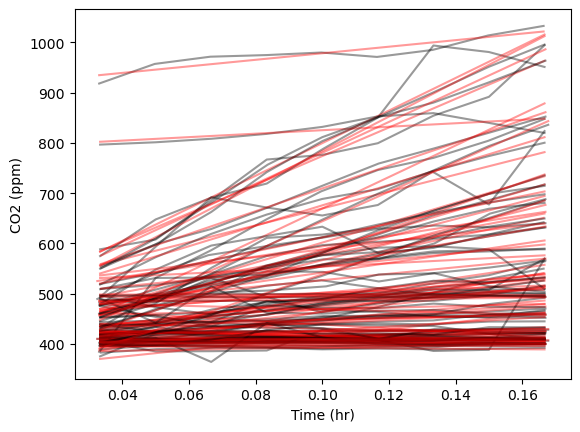

In [62]:
from sklearn.metrics import r2_score

fig, ax = plt.subplots()

extra_cols = ['vol_m3', 'vol_err', 'sa_m2', 'sa_err'] 
vol, vol_err, sa, sa_err = extras[extra_cols].iloc[0]
meta_cols = ['ground','temp','rh','lat','lon','notes','reading_id', 'tod']
time_col = 'UTC Date/Time'  #change this to 'timestamp' if using api folder data

slopes = [] 

x_start_hr = 0.02
x_end_hr = 0.17

for df, g in data.groupby('reading_id'): 
    slope = g[meta_cols].iloc[0] 

    x = g[time_col]
    y = g['co2_cal'].astype(float)

    x -= x.min() 
    x = x.dt.total_seconds() / 3600 

    include1 = x > x_start_hr #only include x values > 0.02 and returns a list of True/False
    include2 = x < x_end_hr #only include x values < 0.016 and returns a list of True/False
    include = include1 & include2 #combine the two lists of True/False to only keep values that are True in both lists
    x = x[include] #Only keeps True x vals
    y = y[include] #And associated y vals

    p, cov = np.polyfit(x, y, 1, cov=True) #linear fit --> assume constant CO2 flux
    
    pred = np.polyval(p, x) #predicted CO2 values according to fit

    slope['dCO2_ppm_dt_hr'] = p[0] # save the slope to our series
    slope['dCO2_ppm_dt_hr_std'] = cov[0,0]**0.5 # Save the standard deviation to our series
    slope['slope_r2'] = r2_score(y, pred) #Calculate R squared value and save to our series
    slope['vol'] = vol
    slope['vol_err'] = vol_err
    slope['sa'] = sa
    slope['sa_err'] = sa_err
    
    slopes.append(slope) #add our meta series (which includes metadata, slopes, and errors for each data file) to slopes list
    
    ###plot raw data vs predicted values for each data file
    
    ax.plot(x,y, color='k', alpha=0.4) 
    
    ax.plot(x, pred, 'r', alpha=0.4)
    ax.set_xlabel('Time (hr)')
    ax.set_ylabel('CO2 (ppm)')

In [63]:
slopes = pd.DataFrame(slopes)



slopes

,ground,temp,rh,lat,lon,notes,reading_id,tod,dCO2_ppm_dt_hr,dCO2_ppm_dt_hr_std,slope_r2,vol,vol_err,sa,sa_err
0,concrete,11.1,57.0,52.18509,0.13425,None,0,morning,-7.896936,7.302932,0.143133,0.00385,0.0001,0.049,0.004
12,concrete,11.1,62.0,52.18512,0.13423,1x car passed,1,morning,1.405297,10.447183,0.002578,0.00385,0.0001,0.049,0.004
24,concrete,9.9,67.0,52.18508,0.13399,None,2,morning,-32.493036,16.799521,0.348291,0.00385,0.0001,0.049,0.004
35,grass,9.6,82.0,52.18488,0.13327,None,3,morning,674.395877,78.595859,0.913179,0.00385,0.0001,0.049,0.004
46,grass,9.5,77.0,52.18456,0.13308,None,4,morning,138.774726,53.646755,0.488740,0.00385,0.0001,0.049,0.004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
847,canopy,4.1,80.0,52.18460,0.13171,None,76,evening,3431.337047,105.794925,0.993390,0.00385,0.0001,0.049,0.004
858,canopy,4.1,83.0,52.18460,0.13171,None,77,evening,3079.403272,178.388902,0.977048,0.00385,0.0001,0.049,0.004
869,concrete,3.2,81.0,52.18510,0.13412,None,78,evening,59.781972,27.342567,0.405791,0.00385,0.0001,0.049,0.004
880,concrete,4.4,81.0,52.18510,0.13412,None,79,evening,-7.868544,9.805341,0.084245,0.00385,0.0001,0.049,0.004


Text(0.5, 1.0, '$R^2$ val')

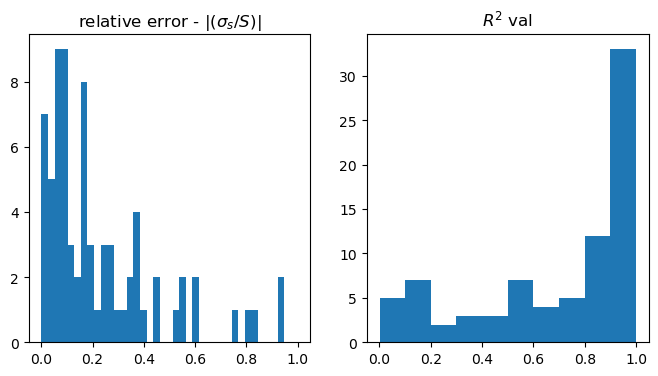

In [58]:
#We can compare errors

plt.figure(figsize=(8,4))
# relative error
plt.subplot(1,2,1)
plt.hist(abs(slopes.dCO2_ppm_dt_hr_std / slopes.dCO2_ppm_dt_hr), bins=np.linspace(0,1,40))
plt.title(r'relative error - $|(\sigma_{s}/S)|$')

#r2
plt.subplot(1,2,2)
plt.hist(slopes.slope_r2)
plt.title(r'$R^2$ val')

Text(0.5, 1.0, 'flux and error by ground type and tod')

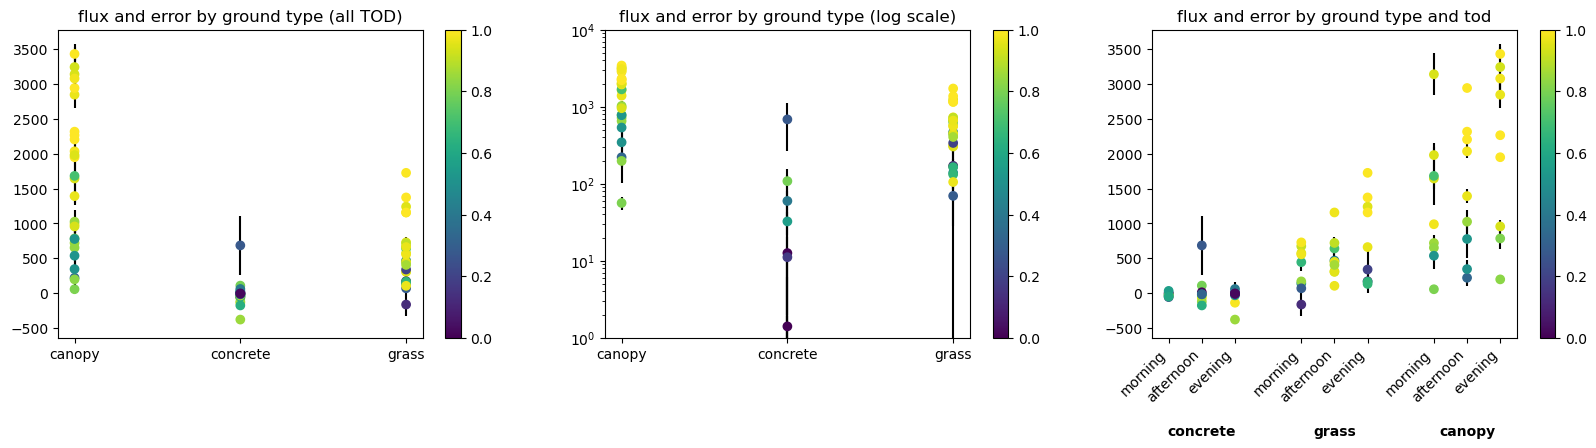

In [59]:
plt.figure(figsize=(20,4))

plt.subplot(1,3,1)
for i, g in slopes.groupby('ground'): 
    plt.errorbar(
        x =g.ground, # x axis is the group number
        y=g.dCO2_ppm_dt_hr, # y axis is the slope for each experiment that group ran
        yerr=g.dCO2_ppm_dt_hr_std, #standard deviation for error bars
        fmt='k.'
    )
    plt.scatter(
        x=g.ground,
        y=g.dCO2_ppm_dt_hr,
        c=g.slope_r2,
        marker='o', zorder=99, vmin=0, vmax=1
    )
plt.colorbar()
plt.title('flux and error by ground type (all TOD)')

plt.subplot(1,3,2)
for i, g in slopes.groupby('ground'): 
    plt.errorbar(
        x =g.ground, # x axis is the group number
        y=g.dCO2_ppm_dt_hr, # y axis is the slope for each experiment that group ran
        yerr=g.dCO2_ppm_dt_hr_std, #standard deviation for error bars
        fmt='k.'
    )
    plt.scatter(
        x=g.ground,
        y=g.dCO2_ppm_dt_hr,
        c=g.slope_r2,
        marker='o', zorder=99, vmin=0, vmax=1
    )
plt.colorbar()
plt.yscale('log')
plt.ylim(1e0, 1e4)
plt.title('flux and error by ground type (log scale)')

ground_order = ['concrete', 'grass', 'canopy']
tod_order =  ['morning', 'afternoon', 'evening']

plt.subplot(1, 3, 3)
ax = plt.gca()

xticks, xlabels = [], []
group_centres = {}
pos = 0
for gname in ground_order:
    start = pos
    g = slopes[slopes['ground'] == gname]
    for t in tod_order:
        h = g[g['tod'] == t]
        if len(h):
            x = np.full(len(h), pos)
            plt.errorbar(x=x, y=h.dCO2_ppm_dt_hr, yerr=h.dCO2_ppm_dt_hr_std, fmt='k.')
            sc = plt.scatter(x=x, y=h.dCO2_ppm_dt_hr, c=h.slope_r2,
                             marker='o', zorder=99, vmin=0, vmax=1)
        xticks.append(pos)
        xlabels.append(t)
        pos += 1
    group_centres[gname] = (start + pos - 1) / 2
    pos += 1          # blank slot between ground types

plt.xticks(xticks, xlabels, rotation=45, ha='right')

# ground name centred under each block of 3
for gname, c in group_centres.items():
    ax.text(c, -0.28, gname, transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontweight='bold')

plt.colorbar(sc)
plt.title('flux and error by ground type and tod')

In [65]:
################### 2. Converting to moles #######################

R = 8.3145
P = 101325

Temp_K = slopes['temp'] + 273.15

slopes['dCO2_mol_dt_hr'] = slopes['dCO2_ppm_dt_hr'] * 1e-6 * P * slopes['vol'] / (R * Temp_K)

slopes['dCO2_mol_dt_hr_std'] = slopes['dCO2_ppm_dt_hr_std'] * 1e-6 * P * slopes['vol'] / (R * Temp_K)


################# 2. Convert to mass ########################

M_CO2 = 44.01

slopes['dCO2_g_dt_hr'] = slopes['dCO2_mol_dt_hr'] * M_CO2
slopes['dCO2_g_dt_hr_std'] = slopes['dCO2_mol_dt_hr_std'] * M_CO2


################### 3. Area normalise #########################

slopes['dCO2_g_dt_hr_m2'] = slopes['dCO2_g_dt_hr'] / slopes['sa']
slopes['dCO2_g_dt_hr_m2_std'] = slopes['dCO2_g_dt_hr_std'] / slopes['sa']

slopes['log_dCO2_g_dt_hr_m2'] = np.log(slopes['dCO2_g_dt_hr_m2'])
slopes

c:\Users\Ealish\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,ground,temp,rh,lat,lon,notes,reading_id,tod,dCO2_ppm_dt_hr,dCO2_ppm_dt_hr_std,...,vol_err,sa,sa_err,dCO2_mol_dt_hr,dCO2_mol_dt_hr_std,dCO2_g_dt_hr,dCO2_g_dt_hr_std,dCO2_g_dt_hr_m2,dCO2_g_dt_hr_m2_std,log_dCO2_g_dt_hr_m2
0,concrete,11.1,57.0,52.18509,0.13425,None,0,morning,-7.896936,7.302932,...,0.0001,0.049,0.004,-1.303465e-06,0.000001,-0.000057,0.000053,-0.001171,0.001083,NaN
12,concrete,11.1,62.0,52.18512,0.13423,1x car passed,1,morning,1.405297,10.447183,...,0.0001,0.049,0.004,2.319577e-07,0.000002,0.000010,0.000076,0.000208,0.001549,-8.476359
24,concrete,9.9,67.0,52.18508,0.13399,None,2,morning,-32.493036,16.799521,...,0.0001,0.049,0.004,-5.386025e-06,0.000003,-0.000237,0.000123,-0.004838,0.002501,NaN
35,grass,9.6,82.0,52.18488,0.13327,None,3,morning,674.395877,78.595859,...,0.0001,0.049,0.004,1.119060e-04,0.000013,0.004925,0.000574,0.100510,0.011714,-2.297499
46,grass,9.5,77.0,52.18456,0.13308,None,4,morning,138.774726,53.646755,...,0.0001,0.049,0.004,2.303576e-05,0.000009,0.001014,0.000392,0.020690,0.007998,-3.878111
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
847,canopy,4.1,80.0,52.18460,0.13171,None,76,evening,3431.337047,105.794925,...,0.0001,0.049,0.004,5.806749e-04,0.000018,0.025556,0.000788,0.521541,0.016080,-0.650968
858,canopy,4.1,83.0,52.18460,0.13171,None,77,evening,3079.403272,178.388902,...,0.0001,0.049,0.004,5.211182e-04,0.000030,0.022934,0.001329,0.468049,0.027114,-0.759182
869,concrete,3.2,81.0,52.18510,0.13412,None,78,evening,59.781972,27.342567,...,0.0001,0.049,0.004,1.014967e-05,0.000005,0.000447,0.000204,0.009116,0.004169,-4.697717
880,concrete,4.4,81.0,52.18510,0.13412,None,79,evening,-7.868544,9.805341,...,0.0001,0.049,0.004,-1.330131e-06,0.000002,-0.000059,0.000073,-0.001195,0.001489,NaN


In [71]:

px.scatter_map(slopes, lat='lat', lon='lon', color='log_dCO2_g_dt_hr_m2', range_color=(-5,0.0001), center={'lat': 52.184, 'lon': 0.133}, zoom=13, hover_data=['ground','tod','notes'])


In [72]:
slopes.to_parquet(data_method_dir / 'slopes.parquet')